<div style=" background-color: RGB(0,114,200);" >
<h1 style="margin: auto; padding: 20px 0; color:#fff; text-align: center">PROJET 4 DATA ANALYST</h1>
<h2 style="margin: auto; padding: 20px 0; color:#fff; text-align: center">Réalisez une étude de santé publique avec R ou Python
</h2>
</div>

# OBJECTIF DE CE NOTEBOOK

Bienvenue dans l'outil plébiscité par les analystes de données Jupyter.

Il s'agit d'un outil permettant de mixer et d'alterner codes, textes et graphique.

Cet outil est formidable pour plusieurs raisons:

+ il permet de tester des lignes de codes au fur et à mesure de votre rédaction, de constater immédiatement le résultat d'un instruction, de la corriger si nécessaire.
+ De rédiger du texte pour expliquer l'approche suivie ou les résultats d'une analyse et de le mettre en forme grâce à du code html ou plus simple avec **Markdown**
+ d'agrémenter de graphiques

Pour vous aider dans vos premiers pas à l'usage de Jupyter et de Python, nous avons rédigé ce notebook en vous indiquant les instructions à suivre.

Il vous suffit pour cela de saisir le code Python répondant à l'instruction donnée.

Vous verrez de temps à autre le code Python répondant à une instruction donnée mais cela est fait pour vous aider à comprendre la nature du travail qui vous est demandée.

Et garder à l'esprit, qu'il n'y a pas de solution unique pour résoudre un problème et qu'il y a autant de résolutions de problèmes que de développeurs ;)...



<div style="background-color: RGB(0,150,250);" >
<h2 style="margin: auto; padding: 20px; color:#fff; ">Etape 1 - Importation des librairies et chargement des fichiers</h2>
</div>

<div style="border: 1px solid RGB(0,150,250);" >
<h3 style="margin: auto; padding: 20px; color: RGB(0,150,250); ">1.1 - Importation des librairies</h3>
</div>

In [1]:
#Importation de la librairie Pandas
import pandas as pd

<div style="border: 1px solid RGB(0,150,250);" >
<h3 style="margin: auto; padding: 20px; color: RGB(0,150,250); ">1.2 - Chargement des fichiers CSV</h3>
</div>

In [2]:
#Importation du fichier population.csv
population = pd.read_csv("data/population.csv")

#Importation du fichier dispo_alimentaire.csv
dispo_alimentaire = pd.read_csv("data/dispo_alimentaire.csv")

#Importation du fichier aide_alimentaire.csv
aide_alimentaire = pd.read_csv("data/aide_alimentaire.csv")

#Importation du fichier sous_nutrition.csv
sous_nutrition = pd.read_csv("data/sous_nutrition.csv")

# Vérification rapide
print(population.shape)
print(dispo_alimentaire.shape)
print(aide_alimentaire.shape)
print(sous_nutrition.shape)


(1416, 3)
(15605, 18)
(1475, 4)
(1218, 3)


<div style="background-color: RGB(0,150,250);" >
<h2 style="margin: auto; padding: 20px; color:#fff; ">Etape 2 - Analyse exploratoire des fichiers</h2>
</div>

<div style="border: 1px solid RGB(0,150,250);" >
<h3 style="margin: auto; padding: 20px; color: RGB(0,150,250); ">2.1 - Analyse exploratoire du fichier population</h3>
</div>

In [3]:
#Afficher les dimensions du dataset
print("Le tableau comporte {} observation(s) ou article(s)".format(population.shape[0]))
print("Le tableau comporte {} colonne(s)".format(population.shape[1]))

Le tableau comporte 1416 observation(s) ou article(s)
Le tableau comporte 3 colonne(s)


In [4]:
#Consulter le nombre de colonnes
population.columns
#La nature des données dans chacune des colonnes
population.info()
#Le nombre de valeurs présentes dans chacune des colonnes
population.count()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1416 entries, 0 to 1415
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Zone    1416 non-null   object 
 1   Année   1416 non-null   int64  
 2   Valeur  1416 non-null   float64
dtypes: float64(1), int64(1), object(1)
memory usage: 33.3+ KB


Zone      1416
Année     1416
Valeur    1416
dtype: int64

### Conclusion – Analyse exploratoire du fichier population
Le fichier **population** contient **1416 lignes** et **3 colonnes** :  
- Zone  
- Année  
- Valeur  

Les données sont **complètes** : aucune valeur manquante n’a été détectée.

Les valeurs de population sont exprimées **en milliers d’habitants**, ce qui implique une **harmonisation des unités** avant de poursuivre les analyses.


#Nous allons harmoniser les unités. Pour cela, nous avons décidé de multiplier la population par 1000
#Multiplication de la colonne valeur par 1000


In [5]:
#changement du nom de la colonne Valeur par Population
population["Population"] = population["Valeur"]*1000
population = population.drop(columns=['Valeur'])


In [6]:
#Affichage les 5 premières lignes de la table pour voir les modifications
population.head(5)

,Zone,Année,Population
0,Afghanistan,2013,32269589.0
1,Afghanistan,2014,33370794.0
2,Afghanistan,2015,34413603.0
3,Afghanistan,2016,35383032.0
4,Afghanistan,2017,36296113.0


<div style="border: 1px solid RGB(0,150,250);" >
<h3 style="margin: auto; padding: 20px; color: RGB(0,150,250); ">2.2 - Analyse exploratoire du fichier disponibilité alimentaire</h3>
</div>

In [7]:
#Afficher les dimensions du dataset
print("Le tableau comporte {} observation(s)".format(dispo_alimentaire.shape[0]))
print("Le tableau comporte {} colonne(s)".format(dispo_alimentaire.shape[1]))

Le tableau comporte 15605 observation(s)
Le tableau comporte 18 colonne(s)


In [8]:
#Consulter le nombre de colonnes
dispo_alimentaire.columns
dispo_alimentaire.info()
dispo_alimentaire.count()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15605 entries, 0 to 15604
Data columns (total 18 columns):
 #   Column                                                         Non-Null Count  Dtype  
---  ------                                                         --------------  -----  
 0   Zone                                                           15605 non-null  object 
 1   Produit                                                        15605 non-null  object 
 2   Origine                                                        15605 non-null  object 
 3   Aliments pour animaux                                          2720 non-null   float64
 4   Autres Utilisations                                            5496 non-null   float64
 5   Disponibilité alimentaire (Kcal/personne/jour)                 14241 non-null  float64
 6   Disponibilité alimentaire en quantité (kg/personne/an)         14015 non-null  float64
 7   Disponibilité de matière grasse en quantité (g/personne/jo

Zone                                                             15605
Produit                                                          15605
Origine                                                          15605
Aliments pour animaux                                             2720
Autres Utilisations                                               5496
Disponibilité alimentaire (Kcal/personne/jour)                   14241
Disponibilité alimentaire en quantité (kg/personne/an)           14015
Disponibilité de matière grasse en quantité (g/personne/jour)    11794
Disponibilité de protéines en quantité (g/personne/jour)         11561
Disponibilité intérieure                                         15382
Exportations - Quantité                                          12226
Importations - Quantité                                          14852
Nourriture                                                       14015
Pertes                                                            4278
Produc

In [9]:
#Affichage les 5 premières lignes de la table
dispo_alimentaire.head()

,Zone,Produit,Origine,Aliments pour animaux,Autres Utilisations,Disponibilité alimentaire (Kcal/personne/jour),Disponibilité alimentaire en quantité (kg/personne/an),Disponibilité de matière grasse en quantité (g/personne/jour),Disponibilité de protéines en quantité (g/personne/jour),Disponibilité intérieure,Exportations - Quantité,Importations - Quantité,Nourriture,Pertes,Production,Semences,Traitement,Variation de stock
0,Afghanistan,Abats Comestible,animale,NaN,NaN,5.0,1.72,0.20,0.77,53.0,NaN,NaN,53.0,NaN,53.0,NaN,NaN,NaN
1,Afghanistan,"Agrumes, Autres",vegetale,NaN,NaN,1.0,1.29,0.01,0.02,41.0,2.0,40.0,39.0,2.0,3.0,NaN,NaN,NaN
2,Afghanistan,Aliments pour enfants,vegetale,NaN,NaN,1.0,0.06,0.01,0.03,2.0,NaN,2.0,2.0,NaN,NaN,NaN,NaN,NaN
3,Afghanistan,Ananas,vegetale,NaN,NaN,0.0,0.00,NaN,NaN,0.0,NaN,0.0,0.0,NaN,NaN,NaN,NaN,NaN
4,Afghanistan,Bananes,vegetale,NaN,NaN,4.0,2.70,0.02,0.05,82.0,NaN,82.0,82.0,NaN,NaN,NaN,NaN,NaN


In [10]:
# Vérification des valeurs manquantes (on NE remplace pas automatiquement les NaN par 0)
# Un NaN signifie 'donnée non disponible' et non '0'
dispo_alimentaire.isna().sum()

Zone                                                                 0
Produit                                                              0
Origine                                                              0
Aliments pour animaux                                            12885
Autres Utilisations                                              10109
Disponibilité alimentaire (Kcal/personne/jour)                    1364
Disponibilité alimentaire en quantité (kg/personne/an)            1590
Disponibilité de matière grasse en quantité (g/personne/jour)     3811
Disponibilité de protéines en quantité (g/personne/jour)          4044
Disponibilité intérieure                                           223
Exportations - Quantité                                           3379
Importations - Quantité                                            753
Nourriture                                                        1590
Pertes                                                           11327
Produc

## Conclusion – Analyse exploratoire du fichier disponibilité alimentaire

Le fichier **dispo_alimentaire** contient **15 605 lignes** et **18 colonnes**.

Il fournit notamment les informations suivantes :
- Zone  
- Produit  
- Origine  
- Disponibilité alimentaire (kcal/personne/jour)  
- Disponibilité alimentaire en quantité (kg/personne/an)  
- Nourriture, Pertes, Production, Importations, Exportations, etc.

Les valeurs manquantes (NaN) n'ont **pas été remplacées par 0**, car un NaN signifie « donnée non disponible » et non « valeur nulle ». Elles sont conservées telles quelles afin de ne pas fausser les calculs.

Les colonnes de quantités (Nourriture, Pertes, Production, Importations, Exportations, Disponibilité intérieure, etc.) sont exprimées initialement en **milliers de tonnes** dans les données FAO. Pour les convertir en **kilogrammes**, on applique le facteur suivant :  
**1 millier de tonnes = 1 000 × 1 000 kg = 1 000 000 kg** (d'où la multiplication par `1_000_000`).

**Attention** : les colonnes déjà exprimées **par personne et par jour/an** (Kcal/personne/jour, kg/personne/an, g/personne/jour) ne sont **pas** converties, car elles sont dans des unités directement interprétables.

In [11]:
# Conversion des colonnes de quantités : milliers de tonnes → kilogrammes
# Facteur : 1 millier de tonnes = 1 000 tonnes = 1 000 000 kg
# NB : les colonnes exprimées par personne (kcal/pers/jour, kg/pers/an, g/pers/jour)
# ne sont PAS converties.

colonnes_a_convertir = [
    "Nourriture",
    "Pertes",
    "Production",
    "Semences",
    "Traitement",
    "Variation de stock",
    "Exportations - Quantité",
    "Importations - Quantité",
    "Disponibilité intérieure",
    "Aliments pour animaux",
    "Autres Utilisations"
]

dispo_alimentaire[colonnes_a_convertir] = dispo_alimentaire[colonnes_a_convertir] * 1_000_000
dispo_alimentaire.head()

,Zone,Produit,Origine,Aliments pour animaux,Autres Utilisations,Disponibilité alimentaire (Kcal/personne/jour),Disponibilité alimentaire en quantité (kg/personne/an),Disponibilité de matière grasse en quantité (g/personne/jour),Disponibilité de protéines en quantité (g/personne/jour),Disponibilité intérieure,Exportations - Quantité,Importations - Quantité,Nourriture,Pertes,Production,Semences,Traitement,Variation de stock
0,Afghanistan,Abats Comestible,animale,NaN,NaN,5.0,1.72,0.20,0.77,53000000.0,NaN,NaN,53000000.0,NaN,53000000.0,NaN,NaN,NaN
1,Afghanistan,"Agrumes, Autres",vegetale,NaN,NaN,1.0,1.29,0.01,0.02,41000000.0,2000000.0,40000000.0,39000000.0,2000000.0,3000000.0,NaN,NaN,NaN
2,Afghanistan,Aliments pour enfants,vegetale,NaN,NaN,1.0,0.06,0.01,0.03,2000000.0,NaN,2000000.0,2000000.0,NaN,NaN,NaN,NaN,NaN
3,Afghanistan,Ananas,vegetale,NaN,NaN,0.0,0.00,NaN,NaN,0.0,NaN,0.0,0.0,NaN,NaN,NaN,NaN,NaN
4,Afghanistan,Bananes,vegetale,NaN,NaN,4.0,2.70,0.02,0.05,82000000.0,NaN,82000000.0,82000000.0,NaN,NaN,NaN,NaN,NaN


In [12]:
#Affichage les 5 premières lignes de la table
dispo_alimentaire.head(5)

,Zone,Produit,Origine,Aliments pour animaux,Autres Utilisations,Disponibilité alimentaire (Kcal/personne/jour),Disponibilité alimentaire en quantité (kg/personne/an),Disponibilité de matière grasse en quantité (g/personne/jour),Disponibilité de protéines en quantité (g/personne/jour),Disponibilité intérieure,Exportations - Quantité,Importations - Quantité,Nourriture,Pertes,Production,Semences,Traitement,Variation de stock
0,Afghanistan,Abats Comestible,animale,NaN,NaN,5.0,1.72,0.20,0.77,53000000.0,NaN,NaN,53000000.0,NaN,53000000.0,NaN,NaN,NaN
1,Afghanistan,"Agrumes, Autres",vegetale,NaN,NaN,1.0,1.29,0.01,0.02,41000000.0,2000000.0,40000000.0,39000000.0,2000000.0,3000000.0,NaN,NaN,NaN
2,Afghanistan,Aliments pour enfants,vegetale,NaN,NaN,1.0,0.06,0.01,0.03,2000000.0,NaN,2000000.0,2000000.0,NaN,NaN,NaN,NaN,NaN
3,Afghanistan,Ananas,vegetale,NaN,NaN,0.0,0.00,NaN,NaN,0.0,NaN,0.0,0.0,NaN,NaN,NaN,NaN,NaN
4,Afghanistan,Bananes,vegetale,NaN,NaN,4.0,2.70,0.02,0.05,82000000.0,NaN,82000000.0,82000000.0,NaN,NaN,NaN,NaN,NaN


<div style="border: 1px solid RGB(0,150,250);" >
<h3 style="margin: auto; padding: 20px; color: RGB(0,150,250); ">2.3 - Analyse exploratoire du fichier aide alimentaire</h3>
</div>

In [13]:
#Afficher les dimensions du dataset
print("Le tableau comporte {} observation(s)".format(aide_alimentaire.shape[0]))
print("Le tableau comporte {} colonne(s)".format(aide_alimentaire.shape[1]))

Le tableau comporte 1475 observation(s)
Le tableau comporte 4 colonne(s)


In [14]:
#Consulter le nombre de colonnes
aide_alimentaire.columns
aide_alimentaire.info()
aide_alimentaire.count()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1475 entries, 0 to 1474
Data columns (total 4 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   Pays bénéficiaire  1475 non-null   object
 1   Année              1475 non-null   int64 
 2   Produit            1475 non-null   object
 3   Valeur             1475 non-null   int64 
dtypes: int64(2), object(2)
memory usage: 46.2+ KB


Pays bénéficiaire    1475
Année                1475
Produit              1475
Valeur               1475
dtype: int64

In [15]:
#Affichage les 5 premières lignes de la table
aide_alimentaire.head()

,Pays bénéficiaire,Année,Produit,Valeur
0,Afghanistan,2013,Autres non-céréales,682
1,Afghanistan,2014,Autres non-céréales,335
2,Afghanistan,2013,Blé et Farin,39224
3,Afghanistan,2014,Blé et Farin,15160
4,Afghanistan,2013,Céréales,40504


In [16]:
#changement du nom de la colonne Pays bénéficiaire par Zone
aide_alimentaire=aide_alimentaire.rename(columns={"Pays bénéficiaire": "Zone"})


In [17]:
# Conversion de la colonne Valeur : tonnes → kilogrammes
# Facteur : 1 tonne = 1 000 kg
# Cette conversion harmonise les unités avec dispo_alimentaire (également en kg)
aide_alimentaire["Valeur"] = aide_alimentaire["Valeur"] * 1000
aide_alimentaire.head()

,Zone,Année,Produit,Valeur
0,Afghanistan,2013,Autres non-céréales,682000
1,Afghanistan,2014,Autres non-céréales,335000
2,Afghanistan,2013,Blé et Farin,39224000
3,Afghanistan,2014,Blé et Farin,15160000
4,Afghanistan,2013,Céréales,40504000


## Conclusion – Analyse exploratoire du fichier aide_alimentaire

Le fichier **aide_alimentaire** contient **1 475 lignes** et **4 colonnes** :

- Zone (anciennement *Pays bénéficiaire*)
- Année
- Produit
- Valeur

Les données sont **complètes** : aucune valeur manquante n’a été détectée.

La colonne **Valeur**, initialement exprimée en **tonnes**, a été convertie en **kilogrammes** afin d’harmoniser les unités avec les autres jeux de données pour la suite de l’analyse.

In [18]:
#Affichage les 5 premières lignes de la table
aide_alimentaire.head(5)

,Zone,Année,Produit,Valeur
0,Afghanistan,2013,Autres non-céréales,682000
1,Afghanistan,2014,Autres non-céréales,335000
2,Afghanistan,2013,Blé et Farin,39224000
3,Afghanistan,2014,Blé et Farin,15160000
4,Afghanistan,2013,Céréales,40504000


<div style="border: 1px solid RGB(0,150,250);" >
<h3 style="margin: auto; padding: 20px; color: RGB(0,150,250); ">2.4 - Analyse exploratoire du fichier sous nutrition</h3>
</div>

In [19]:
#Afficher les dimensions du dataset
print("Le tableau comporte {} observation(s)".format(sous_nutrition.shape[0]))
print("Le tableau comporte {} colonne(s)".format(sous_nutrition.shape[1]))

Le tableau comporte 1218 observation(s)
Le tableau comporte 3 colonne(s)


In [20]:
#Consulter le nombre de colonnes
sous_nutrition.columns
sous_nutrition.info()
sous_nutrition.count()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1218 entries, 0 to 1217
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   Zone    1218 non-null   object
 1   Année   1218 non-null   object
 2   Valeur  624 non-null    object
dtypes: object(3)
memory usage: 28.7+ KB


Zone      1218
Année     1218
Valeur     624
dtype: int64

In [21]:
#Afficher les 5 premières lignes de la table
sous_nutrition.head()

,Zone,Année,Valeur
0,Afghanistan,2012-2014,8.6
1,Afghanistan,2013-2015,8.8
2,Afghanistan,2014-2016,8.9
3,Afghanistan,2015-2017,9.7
4,Afghanistan,2016-2018,10.5


In [22]:
# Conversion en numérique (les valeurs non convertibles deviennent NaN)
# Important : on NE remplace pas les NaN par 0 (donnée manquante ≠ 0 sous-nutrition)
sous_nutrition["Valeur"] = pd.to_numeric(sous_nutrition["Valeur"], errors="coerce")
# Vérification
sous_nutrition.isna().sum()

Zone        0
Année       0
Valeur    714
dtype: int64

In [23]:
#changement du nom de la colonne Valeur pour refléter le contenu réel (millions de personnes)
sous_nutrition = sous_nutrition.rename(columns={"Valeur": "Nb_sous_alimentes_millions"})

### Conversion des unités
Les valeurs de sous-nutrition (colonne **Nb_sous_alimentes_millions**) sont exprimées en **millions de personnes** dans les données FAO.
La conversion en nombre de personnes est réalisée plus bas lors du calcul :
**Nb_personnes_sous_alimentees = Nb_sous_alimentes_millions × 1 000 000**.

In [24]:
#Afficher les 5 premières lignes de la table
sous_nutrition.head(5)

,Zone,Année,Nb_sous_alimentes_millions
0,Afghanistan,2012-2014,8.6
1,Afghanistan,2013-2015,8.8
2,Afghanistan,2014-2016,8.9
3,Afghanistan,2015-2017,9.7
4,Afghanistan,2016-2018,10.5


### Exemple de lecture des données

Par exemple, pour la ligne :

- **Zone** : Afghanistan  
- **Période** : 2012–2014  
- **Valeur** : 8.6  

Cela signifie qu’environ **8,6 millions de personnes** en Afghanistan étaient en situation de sous-nutrition sur la période 2012–2014.


### Conclusion – Analyse exploratoire du fichier sous_nutrition

Le fichier `sous_nutrition` contient 1 218 lignes et 3 colonnes : Zone, Année et Valeur.

La colonne `Valeur` a été convertie en numérique. Les valeurs manquantes (NaN) n'ont **pas été remplacées par 0**, car une donnée manquante ne signifie pas « 0 personne sous-alimentée ». Elles sont conservées telles quelles.

Les données du fichier `sous_nutrition` représentent un **nombre estimé de personnes sous-alimentées exprimé en millions**, et non un pourcentage.  
Ces valeurs correspondent à des moyennes calculées sur des périodes glissantes (par exemple 2012–2014).  
Afin de permettre des comparaisons entre pays de tailles démographiques différentes, ces valeurs ont ensuite été rapportées à la population totale pour calculer une proportion de personnes sous-alimentées.

<div style="border: 1px solid RGB(0,150,250);" >
<h3 style="margin: auto; padding: 20px; color: RGB(0,150,250); ">3.1 - Proportion de personnes en sous nutrition</h3>
</div>

In [25]:
# Jointure entre la table population et la table sous nutrition, en ciblant l'année 2017
# Sélection de l'année cible dans population (2017)
population_2017 = population[population["Année"] == 2017]

# Extraction de l'année de début de période dans sous_nutrition
# Ex: "2017-2019" -> 2017 (année de début, utilisée pour la jointure)
sous_nutrition["Annee_debut"] = sous_nutrition["Année"].str[:4].astype(int)

# Jointure population / sous_nutrition sur Zone et Année = 2017
df_joint = population_2017.merge(
    sous_nutrition,
    left_on=["Zone", "Année"],
    right_on=["Zone", "Annee_debut"],
    how="inner"
)

df_joint.head()

,Zone,Année_x,Population,Année_y,Nb_sous_alimentes_millions,Annee_debut
0,Afghanistan,2017,36296113.0,2017-2019,11.1,2017
1,Afrique du Sud,2017,57009756.0,2017-2019,3.3,2017
2,Albanie,2017,2884169.0,2017-2019,0.1,2017
3,Algérie,2017,41389189.0,2017-2019,1.2,2017
4,Allemagne,2017,82658409.0,2017-2019,NaN,2017


In [26]:
#Affichage du dataset
print(df_joint.shape)
df_joint.head()

(203, 6)


,Zone,Année_x,Population,Année_y,Nb_sous_alimentes_millions,Annee_debut
0,Afghanistan,2017,36296113.0,2017-2019,11.1,2017
1,Afrique du Sud,2017,57009756.0,2017-2019,3.3,2017
2,Albanie,2017,2884169.0,2017-2019,0.1,2017
3,Algérie,2017,41389189.0,2017-2019,1.2,2017
4,Allemagne,2017,82658409.0,2017-2019,NaN,2017


In [27]:
#Calcul et affichage du nombre de personnes en état de sous nutrition

# Conversion des millions en personnes réelles
# Nb_sous_alimentes_millions contient les millions de personnes sous-alimentées
df_joint["Nb_personnes_sous_alimentees"] = df_joint["Nb_sous_alimentes_millions"] * 1_000_000

# Affichage de contrôle
df_joint[["Zone", "Année_x", "Population", "Nb_sous_alimentes_millions", "Nb_personnes_sous_alimentees"]].head()

,Zone,Année_x,Population,Nb_sous_alimentes_millions,Nb_personnes_sous_alimentees
0,Afghanistan,2017,36296113.0,11.1,11100000.0
1,Afrique du Sud,2017,57009756.0,3.3,3300000.0
2,Albanie,2017,2884169.0,0.1,100000.0
3,Algérie,2017,41389189.0,1.2,1200000.0
4,Allemagne,2017,82658409.0,NaN,NaN


### Conclusion – Proportion de personnes en sous-nutrition

En 2017, l’analyse de la proportion de personnes en situation de sous-nutrition met en
évidence de très fortes disparités entre les pays.

Les résultats montrent que certains pays présentent des situations extrêmement critiques.
Haïti affiche la proportion la plus élevée avec près de 49 % de sa population en situation
de sous-nutrition, suivi par la République populaire démocratique de Corée (environ 48 %)
et Madagascar (plus de 43 %).

Ces niveaux indiquent des situations de vulnérabilité alimentaire majeure, où près d’une
personne sur deux est concernée par la sous-nutrition.

<div style="border: 1px solid RGB(0,150,250);" >
<h3 style="margin: auto; padding: 20px; color: RGB(0,150,250); ">3.2 - Nombre théorique de personne qui pourrait être nourries</h3>
</div>

In [28]:
# Jointure population (2017) / dispo_alimentaire
# IMPORTANT : le fichier dispo_alimentaire ne contient PAS de colonne 'Année' :
# il s'agit d'un snapshot pour une année de référence unique (données FAO moyennées).
# On vérifie cela avant la jointure.

# Vérification : dispo_alimentaire ne contient pas de colonne Année
print("Colonnes de dispo_alimentaire :", dispo_alimentaire.columns.tolist())
print("=> Pas de colonne 'Année' : les données correspondent à une seule période de référence.")

# Jointure sur Zone uniquement (population_2017 déjà définie en section 3.1)
df_dispo = population_2017.merge(
    dispo_alimentaire,
    on=["Zone"],
    how="inner"
)

df_dispo.head()


Colonnes de dispo_alimentaire : ['Zone', 'Produit', 'Origine', 'Aliments pour animaux', 'Autres Utilisations', 'Disponibilité alimentaire (Kcal/personne/jour)', 'Disponibilité alimentaire en quantité (kg/personne/an)', 'Disponibilité de matière grasse en quantité (g/personne/jour)', 'Disponibilité de protéines en quantité (g/personne/jour)', 'Disponibilité intérieure', 'Exportations - Quantité', 'Importations - Quantité', 'Nourriture', 'Pertes', 'Production', 'Semences', 'Traitement', 'Variation de stock']
=> Pas de colonne 'Année' : les données correspondent à une seule période de référence.


,Zone,Année,Population,Produit,Origine,Aliments pour animaux,Autres Utilisations,Disponibilité alimentaire (Kcal/personne/jour),Disponibilité alimentaire en quantité (kg/personne/an),Disponibilité de matière grasse en quantité (g/personne/jour),Disponibilité de protéines en quantité (g/personne/jour),Disponibilité intérieure,Exportations - Quantité,Importations - Quantité,Nourriture,Pertes,Production,Semences,Traitement,Variation de stock
0,Afghanistan,2017,36296113.0,Abats Comestible,animale,NaN,NaN,5.0,1.72,0.20,0.77,53000000.0,NaN,NaN,53000000.0,NaN,53000000.0,NaN,NaN,NaN
1,Afghanistan,2017,36296113.0,"Agrumes, Autres",vegetale,NaN,NaN,1.0,1.29,0.01,0.02,41000000.0,2000000.0,40000000.0,39000000.0,2000000.0,3000000.0,NaN,NaN,NaN
2,Afghanistan,2017,36296113.0,Aliments pour enfants,vegetale,NaN,NaN,1.0,0.06,0.01,0.03,2000000.0,NaN,2000000.0,2000000.0,NaN,NaN,NaN,NaN,NaN
3,Afghanistan,2017,36296113.0,Ananas,vegetale,NaN,NaN,0.0,0.00,NaN,NaN,0.0,NaN,0.0,0.0,NaN,NaN,NaN,NaN,NaN
4,Afghanistan,2017,36296113.0,Bananes,vegetale,NaN,NaN,4.0,2.70,0.02,0.05,82000000.0,NaN,82000000.0,82000000.0,NaN,NaN,NaN,NaN,NaN


In [29]:
#Affichage du nouveau dataframe
print(df_dispo.shape)
df_dispo.head()

(15416, 20)


,Zone,Année,Population,Produit,Origine,Aliments pour animaux,Autres Utilisations,Disponibilité alimentaire (Kcal/personne/jour),Disponibilité alimentaire en quantité (kg/personne/an),Disponibilité de matière grasse en quantité (g/personne/jour),Disponibilité de protéines en quantité (g/personne/jour),Disponibilité intérieure,Exportations - Quantité,Importations - Quantité,Nourriture,Pertes,Production,Semences,Traitement,Variation de stock
0,Afghanistan,2017,36296113.0,Abats Comestible,animale,NaN,NaN,5.0,1.72,0.20,0.77,53000000.0,NaN,NaN,53000000.0,NaN,53000000.0,NaN,NaN,NaN
1,Afghanistan,2017,36296113.0,"Agrumes, Autres",vegetale,NaN,NaN,1.0,1.29,0.01,0.02,41000000.0,2000000.0,40000000.0,39000000.0,2000000.0,3000000.0,NaN,NaN,NaN
2,Afghanistan,2017,36296113.0,Aliments pour enfants,vegetale,NaN,NaN,1.0,0.06,0.01,0.03,2000000.0,NaN,2000000.0,2000000.0,NaN,NaN,NaN,NaN,NaN
3,Afghanistan,2017,36296113.0,Ananas,vegetale,NaN,NaN,0.0,0.00,NaN,NaN,0.0,NaN,0.0,0.0,NaN,NaN,NaN,NaN,NaN
4,Afghanistan,2017,36296113.0,Bananes,vegetale,NaN,NaN,4.0,2.70,0.02,0.05,82000000.0,NaN,82000000.0,82000000.0,NaN,NaN,NaN,NaN,NaN


In [30]:
# Création de la colonne dispo_kcal : alias pour la colonne de disponibilité calorique
df_dispo["dispo_kcal"] = df_dispo["Disponibilité alimentaire (Kcal/personne/jour)"]
df_dispo[["Zone", "Population", "dispo_kcal"]].head()


,Zone,Population,dispo_kcal
0,Afghanistan,36296113.0,5.0
1,Afghanistan,36296113.0,1.0
2,Afghanistan,36296113.0,1.0
3,Afghanistan,36296113.0,0.0
4,Afghanistan,36296113.0,4.0


In [31]:
# Calcul du nombre d'humains pouvant être nourris (théorique)

# Constante : besoin moyen journalier par personne
besoin_kcal_jour = 2100

# Kcal totales disponibles par jour (théorique)
# Population est déjà en "personnes" (conversion faite à l'étape 1), donc PAS de ×1000 ici.
df_dispo["kcal_totales_jour"] = df_dispo["Population"] * df_dispo["dispo_kcal"]

# Nombre théorique de personnes pouvant être nourries
df_dispo["nb_personnes_nourries"] = df_dispo["kcal_totales_jour"] / besoin_kcal_jour

# Vérification
df_dispo[["Zone", "Population", "dispo_kcal", "nb_personnes_nourries"]].head()


,Zone,Population,dispo_kcal,nb_personnes_nourries
0,Afghanistan,36296113.0,5.0,86419.316667
1,Afghanistan,36296113.0,1.0,17283.863333
2,Afghanistan,36296113.0,1.0,17283.863333
3,Afghanistan,36296113.0,0.0,0.000000
4,Afghanistan,36296113.0,4.0,69135.453333


In [32]:
# Agrégation par pays : somme du nombre de personnes pouvant être nourries
# (sur tous les produits alimentaires)
df_nourries_pays = (
    df_dispo
    .groupby("Zone", as_index=False)["nb_personnes_nourries"]
    .sum()
    .sort_values(by="nb_personnes_nourries", ascending=False)
)

# Ajout de la population réelle pour comparaison
df_nourries_pays = df_nourries_pays.merge(
    population_2017[["Zone", "Population"]],
    on="Zone",
    how="left"
)

# Ratio : combien de fois la population pourrait-elle être nourrie ?
df_nourries_pays["ratio"] = df_nourries_pays["nb_personnes_nourries"] / df_nourries_pays["Population"]

print(f"Nombre total théorique de personnes pouvant être nourries dans le monde : {df_nourries_pays['nb_personnes_nourries'].sum():,.0f}")
print(f"Population mondiale 2017 : {df_nourries_pays['Population'].sum():,.0f}")
print(f"Ratio mondial : {df_nourries_pays['nb_personnes_nourries'].sum() / df_nourries_pays['Population'].sum():.2f}")
print()
df_nourries_pays.head(10)

Nombre total théorique de personnes pouvant être nourries dans le monde : 9,961,421,251
Population mondiale 2017 : 7,291,900,830
Ratio mondial : 1.37



,Zone,nb_personnes_nourries,Population,ratio
0,"Chine, continentale",2.105819e+09,1.421022e+09,1.481905
1,Inde,1.564339e+09,1.338677e+09,1.168571
2,États-Unis d'Amérique,5.699819e+08,3.250848e+08,1.753333
3,Indonésie,3.498434e+08,2.646510e+08,1.321905
4,Brésil,3.228352e+08,2.078338e+08,1.553333
5,Nigéria,2.454085e+08,1.908732e+08,1.285714
6,Pakistan,2.413692e+08,2.079062e+08,1.160952
7,Fédération de Russie,2.328481e+08,1.455301e+08,1.600000
8,Bangladesh,1.865278e+08,1.596854e+08,1.168095
9,Mexique,1.822937e+08,1.247773e+08,1.460952


### Conclusion – Nombre théorique de personnes pouvant être nourries

À partir des données de disponibilité alimentaire exprimées en kcal par personne et par
jour, nous avons estimé le nombre théorique de personnes pouvant être nourries dans chaque
pays.

L'hypothèse retenue est un besoin moyen de 2 100 kcal par personne et par jour, seuil de
référence utilisé en sécurité alimentaire pour identifier les situations de vulnérabilité.

**Agrégation par pays** : en sommant les disponibilités caloriques de tous les produits pour
chaque pays, puis en divisant par 2 100 kcal/jour, on obtient le nombre théorique de
personnes que chaque pays pourrait nourrir. Le ratio entre ce nombre et la population
réelle permet d'évaluer si la disponibilité alimentaire est théoriquement suffisante.

Les résultats montrent que, dans de nombreux pays, la disponibilité alimentaire théorique
permettrait de couvrir les besoins énergétiques d'une population équivalente, voire
supérieure, à la population réelle. Cela suggère que la sous-nutrition ne résulte pas d'un
manque global de calories, mais principalement de problèmes de répartition, d'accès et
d'utilisation des ressources alimentaires.


<div style="border: 1px solid RGB(0,150,250);" >
<h3 style="margin: auto; padding: 20px; color: RGB(0,150,250); ">3.3 - Nombre théorique de personne qui pourrait être nourrie avec les produits végétaux</h3>
</div>

In [33]:
# Section 3.3 : Filtrage des produits végétaux
# On réutilise kcal_totales_jour et nb_personnes_nourries déjà calculés en 3.2

# Agrégation par pays (tous produits) - pour comparaison ultérieure
df_nourries_total_pays = (
    df_dispo
    .groupby("Zone", as_index=False)["nb_personnes_nourries"]
    .sum()
    .rename(columns={"nb_personnes_nourries": "nb_personnes_nourries_total"})
    .sort_values(by="nb_personnes_nourries_total", ascending=False)
)

df_nourries_total_pays.head()


,Zone,nb_personnes_nourries_total
36,"Chine, continentale",2.105819e+09
68,Inde,1.564339e+09
169,États-Unis d'Amérique,5.699819e+08
69,Indonésie,3.498434e+08
23,Brésil,3.228352e+08


In [34]:
#Calcul du nombre de kcal disponible pour les végétaux
df_vegetaux = df_dispo[df_dispo["Origine"] == "vegetale"]
df_vegetaux.head()

,Zone,Année,Population,Produit,Origine,Aliments pour animaux,Autres Utilisations,Disponibilité alimentaire (Kcal/personne/jour),Disponibilité alimentaire en quantité (kg/personne/an),Disponibilité de matière grasse en quantité (g/personne/jour),...,Importations - Quantité,Nourriture,Pertes,Production,Semences,Traitement,Variation de stock,dispo_kcal,kcal_totales_jour,nb_personnes_nourries
1,Afghanistan,2017,36296113.0,"Agrumes, Autres",vegetale,NaN,NaN,1.0,1.29,0.01,...,40000000.0,39000000.0,2000000.0,3000000.0,NaN,NaN,NaN,1.0,36296113.0,17283.863333
2,Afghanistan,2017,36296113.0,Aliments pour enfants,vegetale,NaN,NaN,1.0,0.06,0.01,...,2000000.0,2000000.0,NaN,NaN,NaN,NaN,NaN,1.0,36296113.0,17283.863333
3,Afghanistan,2017,36296113.0,Ananas,vegetale,NaN,NaN,0.0,0.00,NaN,...,0.0,0.0,NaN,NaN,NaN,NaN,NaN,0.0,0.0,0.000000
4,Afghanistan,2017,36296113.0,Bananes,vegetale,NaN,NaN,4.0,2.70,0.02,...,82000000.0,82000000.0,NaN,NaN,NaN,NaN,NaN,4.0,145184452.0,69135.453333
6,Afghanistan,2017,36296113.0,Bière,vegetale,NaN,NaN,0.0,0.09,NaN,...,3000000.0,3000000.0,NaN,NaN,NaN,NaN,NaN,0.0,0.0,0.000000


In [35]:
#Calcul du nombre d'humains pouvant être nourris avec les végétaux
# 1) On part des lignes "vegetale" (important : .copy() pour éviter SettingWithCopyWarning)
df_vegetaux = df_dispo[df_dispo["Origine"] == "vegetale"].copy()

# 3) Kcal totales disponibles par jour (végétaux uniquement)
df_vegetaux["kcal_totales_jour_vegetaux"] = df_vegetaux["Population"] *  df_vegetaux["dispo_kcal"]

# 4) Nombre théorique de personnes pouvant être nourries (végétaux uniquement)
df_vegetaux["nb_personnes_nourries_vegetaux"] = df_vegetaux["kcal_totales_jour_vegetaux"] / besoin_kcal_jour

# 5) Vérification
df_vegetaux[["Zone", "Population", "dispo_kcal", "kcal_totales_jour_vegetaux", "nb_personnes_nourries_vegetaux"]].head()

,Zone,Population,dispo_kcal,kcal_totales_jour_vegetaux,nb_personnes_nourries_vegetaux
1,Afghanistan,36296113.0,1.0,36296113.0,17283.863333
2,Afghanistan,36296113.0,1.0,36296113.0,17283.863333
3,Afghanistan,36296113.0,0.0,0.0,0.000000
4,Afghanistan,36296113.0,4.0,145184452.0,69135.453333
6,Afghanistan,36296113.0,0.0,0.0,0.000000


### Conclusion – Personnes pouvant être nourries avec les produits végétaux

L’analyse des produits d’origine végétale montre que ceux-ci constituent la principale
source potentielle de calories disponibles pour l’alimentation humaine.

Dans plusieurs pays fortement peuplés, comme la Chine, l’Inde ou les États-Unis, la
disponibilité calorique issue des produits végétaux permettrait théoriquement de nourrir
une très large part de la population.

Ces résultats confirment le rôle central de l’alimentation végétale dans la sécurité
alimentaire mondiale, tout en rappelant que ces estimations restent théoriques et ne
prennent pas en compte les inégalités d’accès, les pertes ou le gaspillage.








<div style="border: 1px solid RGB(0,150,250);" >
<h3 style="margin: auto; padding: 20px; color: RGB(0,150,250); ">3.4 - Utilisation de la disponibilité intérieure</h3>
</div>

In [36]:
# Agrégation par pays : somme des personnes pouvant être nourries (végétaux uniquement)
# nb_personnes_nourries_vegetaux a déjà été calculé en cellule précédente

df_nourries_vegetaux_pays = (
    df_vegetaux
    .groupby("Zone", as_index=False)["nb_personnes_nourries_vegetaux"]
    .sum()
    .sort_values(by="nb_personnes_nourries_vegetaux", ascending=False)
)

df_nourries_vegetaux_pays.head()


,Zone,nb_personnes_nourries_vegetaux
36,"Chine, continentale",1.616581e+09
68,Inde,1.414535e+09
169,États-Unis d'Amérique,4.176565e+08
69,Indonésie,3.269070e+08
23,Brésil,2.409883e+08


In [37]:
# Analyse de la répartition de la disponibilité intérieure
# On calcule la part de chaque utilisation par rapport à la disponibilité intérieure totale

colonnes_utilisation = [
    "Nourriture",
    "Aliments pour animaux",
    "Pertes",
    "Semences",
    "Traitement",
    "Autres Utilisations"
]

# Agrégation mondiale : somme de chaque utilisation
totaux = {}
for col in colonnes_utilisation:
    totaux[col] = df_dispo[col].sum()

dispo_int_totale = df_dispo["Disponibilité intérieure"].sum()

print("=== Répartition de la disponibilité intérieure mondiale ===")
print(f"Disponibilité intérieure totale : {dispo_int_totale:,.0f} kg")
print()
for col, val in totaux.items():
    pct = (val / dispo_int_totale) * 100 if dispo_int_totale > 0 else 0
    print(f"  {col:30s} : {val:>20,.0f} kg  ({pct:5.1f} %)")

# Somme des usages identifiés
somme_usages = sum(totaux.values())
pct_couvert = (somme_usages / dispo_int_totale) * 100 if dispo_int_totale > 0 else 0
print(f"\n  Total usages identifiés       : {somme_usages:>20,.0f} kg  ({pct_couvert:5.1f} %)")
print(f"  Non attribué / résiduel       : {dispo_int_totale - somme_usages:>20,.0f} kg  ({100 - pct_couvert:5.1f} %)")


=== Répartition de la disponibilité intérieure mondiale ===
Disponibilité intérieure totale : 9,733,927,000,000 kg

  Nourriture                     :    4,805,525,000,000 kg  ( 49.4 %)
  Aliments pour animaux          :    1,288,002,000,000 kg  ( 13.2 %)
  Pertes                         :      452,283,000,000 kg  (  4.6 %)
  Semences                       :      153,317,000,000 kg  (  1.6 %)
  Traitement                     :    2,185,641,000,000 kg  ( 22.5 %)
  Autres Utilisations            :      858,771,000,000 kg  (  8.8 %)

  Total usages identifiés       :    9,743,539,000,000 kg  (100.1 %)
  Non attribué / résiduel       :       -9,612,000,000 kg  ( -0.1 %)


### Conclusion – Utilisation de la disponibilité intérieure

L'analyse de la répartition de la disponibilité intérieure met en évidence que l'ensemble
des calories disponibles n'est pas destiné directement à l'alimentation humaine.

La **Nourriture** (alimentation humaine directe) représente la part la plus importante,
mais une part significative est orientée vers :
- **l'alimentation animale**,
- les **pertes** tout au long de la chaîne alimentaire,
- le **traitement** industriel,
- les **semences** et **autres utilisations**.

Ces résultats montrent que la sécurité alimentaire dépend autant des choix d'affectation
des ressources que des volumes globaux produits.

<div style="border: 1px solid RGB(0,150,250);" >
<h3 style="margin: auto; padding: 20px; color: RGB(0,150,250); ">3.5 - Utilisation des céréales</h3>
</div>

In [38]:
#Création d'une liste avec toutes les variables
# Liste des produits céréaliers
liste_cereales = ["Blé", "Riz (Eq Blanchi)", "Orge", "Maïs", "Seigle","Avoine", "Millet", "Sorgho", "Céréales, Autres"]

In [39]:
#Création d'un dataframe avec les informations uniquement pour ces céréales
# Filtrage des produits céréaliers
df_cereales = df_dispo[df_dispo["Produit"].isin(liste_cereales)].copy()

df_cereales.head()

,Zone,Année,Population,Produit,Origine,Aliments pour animaux,Autres Utilisations,Disponibilité alimentaire (Kcal/personne/jour),Disponibilité alimentaire en quantité (kg/personne/an),Disponibilité de matière grasse en quantité (g/personne/jour),...,Importations - Quantité,Nourriture,Pertes,Production,Semences,Traitement,Variation de stock,dispo_kcal,kcal_totales_jour,nb_personnes_nourries
7,Afghanistan,2017,36296113.0,Blé,vegetale,NaN,NaN,1369.0,160.23,4.69,...,1.173000e+09,4.895000e+09,775000000.0,5.169000e+09,322000000.0,NaN,-350000000.0,1369.0,4.968938e+10,2.366161e+07
12,Afghanistan,2017,36296113.0,"Céréales, Autres",vegetale,NaN,NaN,0.0,0.00,0.00,...,0.000000e+00,0.000000e+00,NaN,NaN,NaN,NaN,NaN,0.0,0.000000e+00,0.000000e+00
32,Afghanistan,2017,36296113.0,Maïs,vegetale,200000000.0,NaN,21.0,2.50,0.30,...,1.000000e+06,7.600000e+07,31000000.0,3.120000e+08,5000000.0,NaN,NaN,21.0,7.622184e+08,3.629611e+05
34,Afghanistan,2017,36296113.0,Millet,vegetale,NaN,NaN,3.0,0.40,0.02,...,NaN,1.200000e+07,1000000.0,1.300000e+07,0.0,NaN,NaN,3.0,1.088883e+08,5.185159e+04
40,Afghanistan,2017,36296113.0,Orge,vegetale,360000000.0,NaN,26.0,2.92,0.24,...,1.000000e+07,8.900000e+07,52000000.0,5.140000e+08,22000000.0,NaN,0.0,26.0,9.436989e+08,4.493804e+05


In [40]:
# Remplacement des NaN par 0 UNIQUEMENT pour la colonne 'Aliments pour animaux'
# Justification : dans le contexte des céréales, un NaN pour 'Aliments pour animaux'
# signifie que ce produit n'est PAS utilisé pour l'alimentation animale dans ce pays.
# Il est donc légitime de remplacer par 0 (aucune quantité destinée aux animaux).
# Cela ne contredit PAS la politique générale de conservation des NaN, car ici
# l'absence de donnée a une signification métier claire (= pas d'usage animal).

df_cereales["Aliments pour animaux"] = df_cereales["Aliments pour animaux"].fillna(0)

# Calcul de la proportion de céréales destinée à l'alimentation animale
# On utilise la 'Disponibilité intérieure' (en kg) comme dénominateur
# car c'est la quantité totale disponible dans le pays pour chaque produit
df_cereales["part_animale"] = (
    df_cereales["Aliments pour animaux"] / df_cereales["Disponibilité intérieure"]
)

df_cereales[["Zone", "Produit", "Aliments pour animaux", "Disponibilité intérieure", "part_animale"]].head()

,Zone,Produit,Aliments pour animaux,Disponibilité intérieure,part_animale
7,Afghanistan,Blé,0.0,5.992000e+09,0.000000
12,Afghanistan,"Céréales, Autres",0.0,0.000000e+00,NaN
32,Afghanistan,Maïs,200000000.0,3.130000e+08,0.638978
34,Afghanistan,Millet,0.0,1.300000e+07,0.000000
40,Afghanistan,Orge,360000000.0,5.240000e+08,0.687023


In [41]:
#Affichage de la proportion d'alimentation animale
# Agrégation par pays
df_part_animale_pays = (
    df_cereales
    .groupby("Zone", as_index=False)["part_animale"]
    .mean()
    .sort_values(by="part_animale", ascending=False)
)

df_part_animale_pays.head(10)

,Zone,part_animale
48,Espagne,0.751619
44,Danemark,0.746391
16,Belgique,0.741501
53,France,0.734026
119,Pays-Bas,0.713299
67,Hongrie,0.713211
145,Suisse,0.696486
75,Italie,0.675810
74,Israël,0.665713
89,Luxembourg,0.659765


### Conclusion – Utilisation des céréales

L’analyse de l’utilisation des céréales révèle une concurrence importante entre
l’alimentation humaine et l’alimentation animale.

La proportion de céréales destinées à l’alimentation animale est calculée en rapportant
les quantités utilisées pour l’alimentation animale à la disponibilité intérieure totale
(toutes deux exprimées en kg).

Ces résultats montrent que la disponibilité alimentaire ne dépend pas uniquement de la
production céréalière, mais aussi des choix d’affectation, qui peuvent limiter l’impact
direct de ces productions sur l’alimentation humaine.


<div style="border: 1px solid RGB(0,150,250);" >
<h3 style="margin: auto; padding: 20px; color: RGB(0,150,250); ">3.6 - Pays avec la proportion de personnes sous-alimentée la plus forte en 2017</h3>
</div>

In [42]:
#Création de la colonne proportion par pays
# 3.6 - Pays avec la plus forte proportion de personnes sous-alimentées en 2017

df_prop = df_joint.copy()

# Calcul de la proportion de personnes sous-alimentées
# proportion = nombre de personnes sous-alimentées / population totale
df_prop["proportion_sous_alimentee"] = (
    df_prop["Nb_personnes_sous_alimentees"] / df_prop["Population"]
)


# Vérification rapide
df_prop[["Zone", "Population", "Nb_personnes_sous_alimentees", "proportion_sous_alimentee"]].head()



,Zone,Population,Nb_personnes_sous_alimentees,proportion_sous_alimentee
0,Afghanistan,36296113.0,11100000.0,0.305818
1,Afrique du Sud,57009756.0,3300000.0,0.057885
2,Albanie,2884169.0,100000.0,0.034672
3,Algérie,41389189.0,1200000.0,0.028993
4,Allemagne,82658409.0,NaN,NaN


In [43]:
#affichage après trie des 10 pires pays
# Tri décroissant sur la proportion de sous-nutrition
top10_sous_alimentation = (
    df_prop[["Zone", "proportion_sous_alimentee"]]
    .dropna()
    .sort_values(by="proportion_sous_alimentee", ascending=False)
    .head(10)
)

top10_sous_alimentation

,Zone,proportion_sous_alimentee
78,Haïti,0.491697
157,République populaire démocratique de Corée,0.479752
108,Madagascar,0.430183
183,Tchad,0.406213
103,Libéria,0.382797
161,Rwanda,0.367249
121,Mozambique,0.335090
100,Lesotho,0.334683
186,Timor-Leste,0.321735
198,Venezuela (République bolivarienne du),0.309498


### Conclusion – Pays avec la plus forte proportion de personnes sous-alimentées en 2017

L’analyse des proportions de sous-nutrition met en évidence des situations particulièrement
critiques dans certains pays.

Haïti se distingue avec près de 49 % de sa population en situation de sous-nutrition,
suivi par la République populaire démocratique de Corée (environ 48 %) et Madagascar
(plus de 43 %).

Ces pays combinent une faible disponibilité alimentaire et des contraintes économiques,
politiques ou structurelles fortes, ce qui aggrave durablement leur vulnérabilité
alimentaire.

<div style="border: 1px solid RGB(0,150,250);" >
<h3 style="margin: auto; padding: 20px; color: RGB(0,150,250); ">3.7 - Pays qui ont le plus bénéficié d'aide alimentaire depuis 2013</h3>
</div>

In [44]:
#calcul du total de l'aide alimentaire par pays
# On vérifie rapidement les colonnes disponibles
aide_alimentaire.columns
# Renommage de la colonne Valeur pour que ce soit plus clair
aide = aide_alimentaire.rename(columns={"Valeur": "Aide_alimentaire"})

# Total d'aide alimentaire par pays (toutes années confondues)
aide_par_pays = (
    aide
    .groupby("Zone", as_index=False)["Aide_alimentaire"]
    .sum()
)

aide_par_pays.head()

,Zone,Aide_alimentaire
0,Afghanistan,185452000
1,Algérie,81114000
2,Angola,5014000
3,Bangladesh,348188000
4,Bhoutan,2666000


In [45]:
#affichage après trie des 10 pays qui ont bénéficié le plus de l'aide alimentaire
top10_aide = aide_par_pays.sort_values(
    by="Aide_alimentaire",
    ascending=False
).head(10)

top10_aide

,Zone,Aide_alimentaire
50,République arabe syrienne,1858943000
75,Éthiopie,1381294000
70,Yémen,1206484000
61,Soudan du Sud,695248000
60,Soudan,669784000
30,Kenya,552836000
3,Bangladesh,348188000
59,Somalie,292678000
53,République démocratique du Congo,288502000
43,Niger,276344000


### Conclusion – Pays ayant le plus bénéficié de l’aide alimentaire depuis 2013

L’agrégation des volumes d’aide alimentaire montre une forte concentration sur un nombre
limité de pays.

La République arabe syrienne, l’Éthiopie, le Yémen, le Soudan du Sud et le Soudan figurent
parmi les principaux bénéficiaires, avec des volumes cumulés très élevés sur la période
étudiée.

Ces résultats reflètent l’intensité et la durée des crises humanitaires, liées notamment
aux conflits armés, à l’instabilité politique et aux chocs climatiques.

<div style="border: 1px solid RGB(0,150,250);" >
<h3 style="margin: auto; padding: 20px; color: RGB(0,150,250); ">3.8 - Evolution des 5 pays qui ont le plus bénéficiés de l'aide alimentaire entre 2013 et 2016</h3>
</div>

In [46]:
#Création d'un dataframe avec la zone, l'année et l'aide alimentaire puis groupby sur zone et année 
# DataFrame avec uniquement les colonnes utiles
aide_zone_annee = aide[["Zone", "Année", "Aide_alimentaire"]]

# Agrégation par pays et par année
aide_zone_annee = (
    aide_zone_annee
    .groupby(["Zone", "Année"], as_index=False)
    .sum()
)

aide_zone_annee.head()


,Zone,Année,Aide_alimentaire
0,Afghanistan,2013,128238000
1,Afghanistan,2014,57214000
2,Algérie,2013,35234000
3,Algérie,2014,18980000
4,Algérie,2015,17424000


In [47]:
#Création d'une liste contenant les 5 pays qui ont le plus bénéficiées de l'aide alimentaire
top5_pays = top10_aide["Zone"].head(5).tolist()
top5_pays

['République arabe syrienne', 'Éthiopie', 'Yémen', 'Soudan du Sud', 'Soudan']

In [48]:
#On filtre sur le dataframe avec notre liste
aide_top5 = aide_zone_annee[aide_zone_annee["Zone"].isin(top5_pays)]
aide_top5.head()

,Zone,Année,Aide_alimentaire
157,République arabe syrienne,2013,563566000
158,République arabe syrienne,2014,651870000
159,République arabe syrienne,2015,524949000
160,République arabe syrienne,2016,118558000
189,Soudan,2013,330230000


In [49]:
# Affichage des pays avec l'aide alimentaire par année
aide_top5.sort_values(["Zone", "Année"])

,Zone,Année,Aide_alimentaire
157,République arabe syrienne,2013,563566000
158,République arabe syrienne,2014,651870000
159,République arabe syrienne,2015,524949000
160,République arabe syrienne,2016,118558000
189,Soudan,2013,330230000
190,Soudan,2014,321904000
191,Soudan,2015,17650000
192,Soudan du Sud,2013,196330000
193,Soudan du Sud,2014,450610000
194,Soudan du Sud,2015,48308000


### Conclusion – Évolution de l’aide alimentaire entre 2013 et 2016

L’analyse de l’évolution annuelle de l’aide alimentaire pour les cinq pays les plus aidés
montre une forte variabilité selon les années.

La République arabe syrienne connaît un pic important d’aide à partir de 2014, tandis que
le Yémen voit une augmentation marquée à partir de 2015. À l’inverse, certains pays
présentent des volumes plus fluctuants.

Ces évolutions confirment que l’aide alimentaire est principalement réactive et suit
l’aggravation des crises humanitaires plutôt qu’une logique structurelle de long terme.

<div style="border: 1px solid RGB(0,150,250);" >
<h3 style="margin: auto; padding: 20px; color: RGB(0,150,250); ">3.9 - Pays avec le moins de disponibilité par habitant</h3>
</div>

In [50]:
#Calcul de la disponibilité en kcal par personne par jour par pays
# Calcul de la disponibilité alimentaire moyenne par personne et par jour par pays

# On part du dataframe df_dispo qui contient déjà la colonne dispo_kcal

dispo_par_pays = (
    df_dispo
    .groupby("Zone", as_index=False)["dispo_kcal"]
    .sum()
)
dispo_par_pays.head()

,Zone,dispo_kcal
0,Afghanistan,2087.0
1,Afrique du Sud,3020.0
2,Albanie,3188.0
3,Algérie,3293.0
4,Allemagne,3503.0


In [51]:
#Affichage des 10 pays qui ont le moins de dispo alimentaire par personne 

top10_moins_dispo = dispo_par_pays.sort_values(
    by="dispo_kcal",
    ascending=True
).head(10)

top10_moins_dispo

,Zone,dispo_kcal
127,République centrafricaine,1879.0
164,Zambie,1924.0
91,Madagascar,2056.0
0,Afghanistan,2087.0
65,Haïti,2089.0
132,République populaire démocratique de Corée,2093.0
150,Tchad,2109.0
165,Zimbabwe,2113.0
114,Ouganda,2126.0
152,Timor-Leste,2129.0


### Conclusion – Pays avec la plus faible disponibilité alimentaire par habitant

L’analyse de la disponibilité alimentaire par habitant met en évidence plusieurs pays
situés sous ou très proches du seuil critique de 2 100 kcal par jour et par personne.

La République centrafricaine, Madagascar, l’Afghanistan et Haïti figurent parmi les pays
ayant les niveaux de disponibilité calorique les plus faibles.

Ces résultats traduisent une situation de forte vulnérabilité alimentaire et un risque
accru de sous-nutrition pour les populations concernées.

<div style="border: 1px solid RGB(0,150,250);" >
<h3 style="margin: auto; padding: 20px; color: RGB(0,150,250); ">3.10 - Pays avec le plus de disponibilité par habitant</h3>
</div>

In [52]:
#Affichage des 10 pays qui ont le plus de dispo alimentaire par personne 
# Affichage des 10 pays avec le plus de disponibilité alimentaire par personne

top10_plus_dispo = dispo_par_pays.sort_values(
    by="dispo_kcal",
    ascending=False
).head(10)

top10_plus_dispo

,Zone,dispo_kcal
11,Autriche,3770.0
16,Belgique,3737.0
157,Turquie,3708.0
169,États-Unis d'Amérique,3682.0
74,Israël,3610.0
72,Irlande,3602.0
75,Italie,3578.0
89,Luxembourg,3540.0
166,Égypte,3518.0
4,Allemagne,3503.0


### Conclusion – Pays avec la plus forte disponibilité alimentaire par habitant

À l’inverse, certains pays présentent une disponibilité alimentaire très élevée,
dépassant largement 3 500 kcal par jour et par personne.

Des pays comme l’Autriche, la Belgique, les États-Unis ou l’Italie illustrent des situations
d’abondance calorique.

Ces écarts soulignent l’existence de fortes inégalités mondiales en matière d’accès aux
ressources alimentaires.

<div style="border: 1px solid RGB(0,150,250);" >
<h3 style="margin: auto; padding: 20px; color: RGB(0,150,250); ">3.11 - Exemple de la Thaïlande pour le Manioc</h3>
</div>

In [53]:
#création d'un dataframe avec uniquement la Thaïlande 
# Filtrage sur la Thaïlande et le produit Manioc
thailande_manioc = df_dispo[
    (df_dispo["Zone"] == "Thaïlande") &
    (df_dispo["Produit"] == "Manioc")
].copy()

thailande_manioc.head()

,Zone,Année,Population,Produit,Origine,Aliments pour animaux,Autres Utilisations,Disponibilité alimentaire (Kcal/personne/jour),Disponibilité alimentaire en quantité (kg/personne/an),Disponibilité de matière grasse en quantité (g/personne/jour),...,Importations - Quantité,Nourriture,Pertes,Production,Semences,Traitement,Variation de stock,dispo_kcal,kcal_totales_jour,nb_personnes_nourries
14166,Thaïlande,2017,69209810.0,Manioc,vegetale,1.800000e+09,2.081000e+09,40.0,13.0,0.05,...,1.250000e+09,871000000.0,1.511000e+09,3.022800e+10,NaN,0.0,0.0,40.0,2.768392e+09,1.318282e+06


In [54]:
#Calcul de la sous nutrition en Thaïlande
# 1) Types cohérents
thailande_manioc["Année"] = thailande_manioc["Année"].astype(int)
sous_nutrition["Année"] = pd.to_numeric(sous_nutrition["Année"], errors="coerce")

# 2) Filtre sous-nutrition pour la Thaïlande (si existe)
sn_thai = sous_nutrition.loc[
    sous_nutrition["Zone"] == "Thaïlande",
    ["Zone", "Année", "Nb_sous_alimentes_millions"]
].copy()

# 3) Jointure
df_thai_sous_nut = thailande_manioc.merge(
    sn_thai,
    on=["Zone", "Année"],
    how="left"
)

# 4) Si aucune donnée trouvée, on remplace NaN (au choix : 0 ou "Non disponible")
df_thai_sous_nut["Nb_sous_alimentes_millions"] = df_thai_sous_nut["Nb_sous_alimentes_millions"].fillna(0)

# 5) Affichage final
df_thai_sous_nut[["Zone", "Année", "Produit", "Population", "Nb_sous_alimentes_millions"]]
 

,Zone,Année,Produit,Population,Nb_sous_alimentes_millions
0,Thaïlande,2017,Manioc,69209810.0,0.0


In [55]:
# On calcule la proportion exportée en fonction de la production
# 1) On identifie automatiquement les bonnes colonnes
col_production = "Production"

col_export = [c for c in thailande_manioc.columns 
              if "Export" in c][0]

# 2) Calcul de la proportion exportée (exportations / production)
thailande_manioc["proportion_exportee"] = (
    thailande_manioc[col_export] / thailande_manioc[col_production]
)

# 3) Affichage du résultat
thailande_manioc[
    ["Zone", "Année", "Produit", col_production, col_export, "proportion_exportee"]
]

,Zone,Année,Produit,Production,Exportations - Quantité,proportion_exportee
14166,Thaïlande,2017,Manioc,3.022800e+10,2.521400e+10,0.834127


### Conclusion – Exemple de la Thaïlande pour le manioc

En 2017, la Thaïlande exporte environ 83 % de sa production de manioc, tandis que la part
destinée à l’alimentation intérieure reste limitée.

Cet exemple montre qu’une production agricole élevée ne garantit pas nécessairement une
meilleure sécurité alimentaire pour la population locale.

Il met en évidence l’importance des choix d’orientation des productions agricoles entre
marchés internationaux et consommation intérieure dans l’analyse de la sécurité
alimentaire.








<div style="background-color: RGB(0,150,250);" >
<h2 style="margin: auto; padding: 20px; color:#fff; ">Etape 3 - Analyse complémentaires</h2>
</div>


Cette étape permet d’approfondir l’analyse afin de mieux comprendre les déséquilibres entre production, exportations et sécurité alimentaire.

### Limites des données

Les indicateurs utilisés reposent sur des moyennes nationales. Ils ne prennent pas en compte :
- les inégalités de répartition au sein des pays,
- les pertes post-récolte,
- les difficultés logistiques,
- les différences de consommation selon les régions ou les catégories sociales.

Ainsi, une disponibilité alimentaire élevée ne garantit pas automatiquement une bonne sécurité alimentaire pour l’ensemble de la population.

### Rôle du commerce international

L’exemple de la Thaïlande pour le manioc montre que certains produits sont massivement orientés vers l’exportation.  
Même lorsqu’un pays dispose d’une production importante, une grande part peut être destinée au marché international, ce qui limite l’impact direct sur l’alimentation locale.

### Enseignements principaux

- Plusieurs pays en situation de sous-nutrition importante figurent parmi les principaux bénéficiaires de l’aide alimentaire.
- Les pays ayant la plus faible disponibilité calorique par habitant sont majoritairement situés en Afrique subsaharienne.
- À l’inverse, les pays ayant la plus forte disponibilité par habitant sont principalement des pays développés.

Ces constats confirment que la faim dans le monde est moins liée à une pénurie globale de nourriture qu’à des problèmes de **répartition, d’accès et de priorités économiques**.


In [56]:
top10_sous_alimentation.head()


,Zone,proportion_sous_alimentee
78,Haïti,0.491697
157,République populaire démocratique de Corée,0.479752
108,Madagascar,0.430183
183,Tchad,0.406213
103,Libéria,0.382797


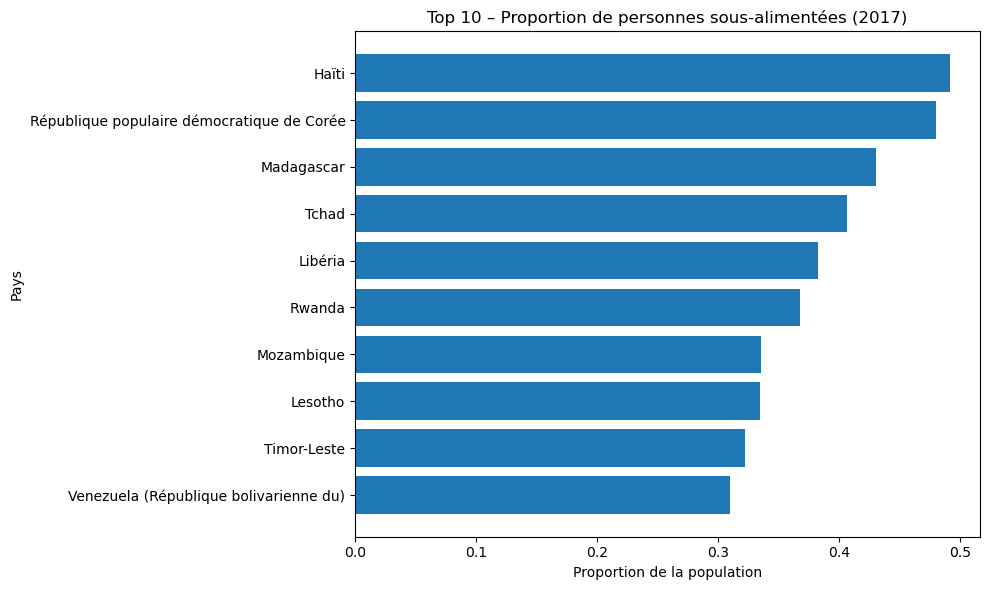

In [57]:
import matplotlib.pyplot as plt

top10 = top10_sous_alimentation.sort_values(
    "proportion_sous_alimentee", ascending=True
)

plt.figure(figsize=(10, 6))
plt.barh(top10["Zone"], top10["proportion_sous_alimentee"])
plt.title("Top 10 – Proportion de personnes sous-alimentées (2017)")
plt.xlabel("Proportion de la population")
plt.ylabel("Pays")
plt.tight_layout()
plt.show()

##Interprétation-Slide 4 –Top 10 des pays présentant la plus forte proportion de personnes sous-alimentées (2017)

Ce graphique met en évidence une forte disparité entre les pays analysés. En 2017, **Haïti** présente la proportion la plus élevée de personnes sous-alimentées (≈ **49 %**), suivi de la **Corée du Nord** (≈ **48 %**).  
Ces résultats soulignent que certains pays connaissent une situation alimentaire extrêmement critique, avec près d’une personne sur deux concernée par la sous-nutrition.

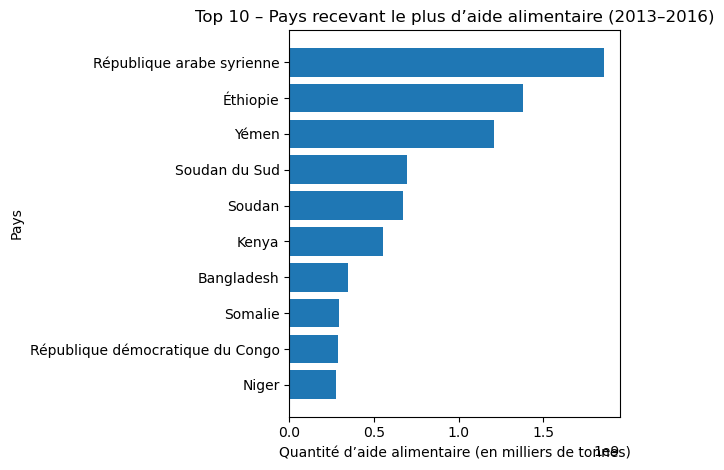

In [58]:
top10 = top10_aide.sort_values("Aide_alimentaire", ascending=True)

plt.figure()
plt.barh(top10["Zone"], top10["Aide_alimentaire"])
plt.title("Top 10 – Pays recevant le plus d’aide alimentaire (2013–2016)")
plt.xlabel("Quantité d’aide alimentaire (en milliers de tonnes)")
plt.ylabel("Pays")
plt.tight_layout()
plt.show()

##Interprétation-Slide 6 – Top 10 des pays recevant le plus d’aide alimentaire (2013–2016)

La République arabe syrienne apparaît comme le principal bénéficiaire de l’aide alimentaire sur la période 2013–2016, devant l’Éthiopie et le Yémen. Ces pays sont majoritairement confrontés à des crises humanitaires prolongées ou à des conflits armés.

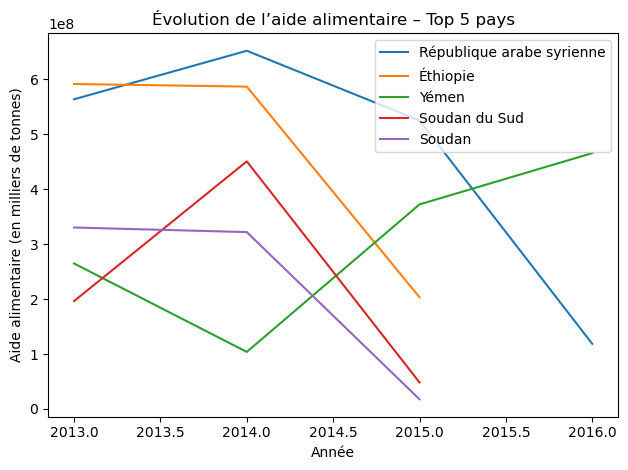

In [59]:
plt.figure()
for pays in top5_pays:
    tmp = aide_top5[aide_top5["Zone"] == pays].sort_values("Année")
    plt.plot(tmp["Année"], tmp["Aide_alimentaire"], label=pays)

plt.title("Évolution de l’aide alimentaire – Top 5 pays")
plt.xlabel("Année")
plt.ylabel("Aide alimentaire (en milliers de tonnes)")
plt.legend()
plt.tight_layout()
plt.show()

##Interprétation-Slide 7  – Évolution de l’aide alimentaire pour les cinq principaux pays bénéficiaires

L’analyse de l’évolution de l’aide alimentaire entre 2013 et 2016 révèle des trajectoires contrastées selon les pays. On observe notamment une diminution progressive de l’aide pour la République arabe syrienne après 2014, tandis que le Yémen connaît une augmentation continue sur la période observée. Les données ne sont pas disponibles pour tous les pays sur l’ensemble de la période, ce qui explique que certaines courbes s’arrêtent avant 2016.

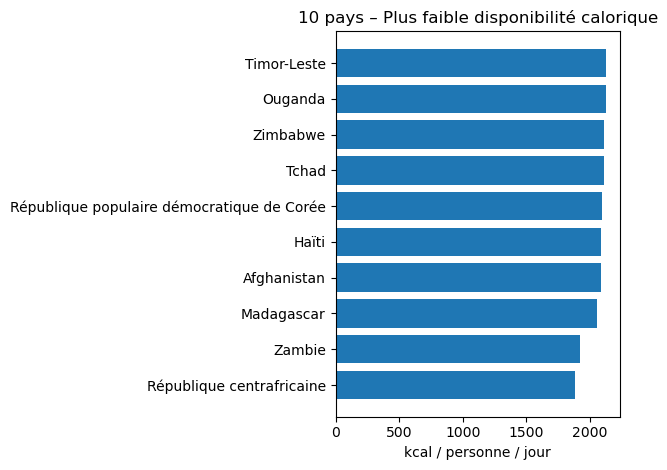

In [60]:
plt.figure()
plt.barh(top10_moins_dispo["Zone"], top10_moins_dispo["dispo_kcal"])
plt.title("10 pays – Plus faible disponibilité calorique")
plt.xlabel("kcal / personne / jour")
plt.tight_layout()
plt.show()

##Interprétation- Slide 8 – Dix pays présentant la plus faible disponibilité calorique

Ce graphique met en évidence les dix pays disposant de la plus faible disponibilité calorique moyenne par personne et par jour. Plusieurs de ces pays se situent en dessous du seuil minimal recommandé d’environ 2 100 kcal par personne et par jour, traduisant des situations de forte vulnérabilité alimentaire.

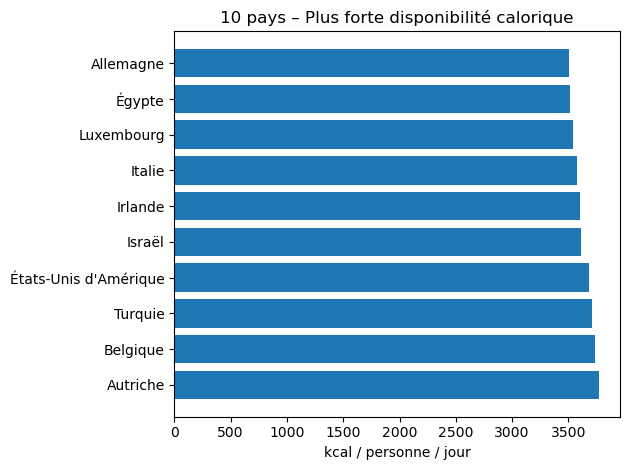

In [61]:
plt.figure()
plt.barh(top10_plus_dispo["Zone"], top10_plus_dispo["dispo_kcal"])
plt.title("10 pays – Plus forte disponibilité calorique")
plt.xlabel("kcal / personne / jour")
plt.tight_layout()
plt.show()

##Interprétation- Slide 9 – Dix pays présentant la plus forte disponibilité calorique

Les pays figurant dans ce graphique présentent une disponibilité calorique moyenne par personne et par jour largement supérieure aux besoins énergétiques minimaux. Ces résultats reflètent des systèmes agricoles et logistiques performants, garantissant une disponibilité alimentaire élevée.

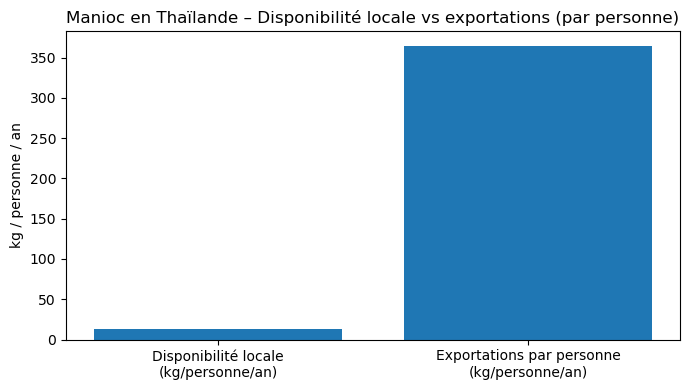

In [62]:
import matplotlib.pyplot as plt

col_dispo = "Disponibilité alimentaire en quantité (kg/personne/an)"
col_export_total = "Exportations - Quantité"
col_pop = "Population"

dispo = thailande_manioc[col_dispo].iloc[0]
export_total = thailande_manioc[col_export_total].iloc[0]
pop = thailande_manioc[col_pop].iloc[0]

export_par_personne = export_total / pop  # kg/personne/an (si export_total est en kg/an)

plt.figure(figsize=(7,4))
plt.bar(
    ["Disponibilité locale\n(kg/personne/an)", "Exportations par personne\n(kg/personne/an)"],
    [dispo, export_par_personne]
)
plt.title("Manioc en Thaïlande – Disponibilité locale vs exportations (par personne)")
plt.ylabel("kg / personne / an")
plt.tight_layout()
plt.show()

##Interprétation- Slide 10 – Manioc en Thaïlande : comparaison entre disponibilité locale et exportations (par personne)

En ramenant les exportations de manioc à une valeur par habitant, on observe que la quantité exportée par personne est très supérieure à la disponibilité alimentaire locale. Cette comparaison met en évidence une forte orientation de la production de manioc vers l’exportation, au détriment de la disponibilité intérieure.